# **Create Visualizations using Matplotlib, Seaborn and Folium**

Analyzing the Impact of Recession on Automobile Sales

Estimated time needed: **40** minutes


# Scenario

In this assignment you will be tasked with creating plots which answer questions for analysing "historical_automobile_sales" data to understand the historical trends in automobile sales during recession periods.

recession period 1 - year 1980 
recession period 2 - year 1981 to 1982
recession period 3 - year 1991
recession period 4 - year 2000 to 2001
recession period 5 - year end 2007 to mid 2009
recession period 6 - year 2020 -Feb to April (Covid-19 Impact)

## Data Description

The dataset contains *historical_automobile_sales* data representing automobile sales and related variables during recession and non-recession periods.

Variables: Date, Recession (1=recession, 0=normal), Automobile_Sales, GDP, Unemployment_Rate, Consumer_Confidence, Seasonality_Weight, Price, Advertising_Expenditure, Vehicle_Type, Competition, Month, Year, City.

In [ ]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium
print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import requests
import io

# URL of the CSV file
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/historical_automobile_sales.csv"

# Fetch the data from the URL
response = requests.get(URL)
response.raise_for_status()

# Read the CSV data into a pandas dataframe
csv_content = io.StringIO(response.text)
df = pd.read_csv(csv_content)

print("Data downloaded and read into a dataframe!")
print(df.head())

Data downloaded and read into a dataframe!
         Date  Year Month  Recession  Consumer_Confidence  Seasonality_Weight  \
0  1/31/1980  1980   Jan          1                 85.0                 1.0   
1  2/29/1980  1980   Feb          1                 87.0                 0.9   

   Price  Advertising_Expenditure  Competition       GDP  Growth_Rate  \
0  25000.0                     5000           10  25000.0         0.02   

   unemployment_rate  Automobile_Sales   Vehicle_Type      City  
0                9.5             456.0  Supperminicar   Georgia  


In [ ]:
df.describe()

            Year   Recession  Consumer_Confidence  Seasonality_Weight  \
count  840.000000  840.000000           840.000000          840.000000   
mean  2000.500000    0.107143           100.000000            1.000000   


In [ ]:
df.head()

         Date  Year Month  ...  Vehicle_Type      City
0  1/31/1980  1980   Jan  ...  Supperminicar   Georgia
[5 rows x 15 columns]

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 840 entries, 0 to 839
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Date                     840 non-null    object 
 1   Year                     840 non-null    int64  
 2   Month                    840 non-null    object 
 3   Recession                840 non-null    int64  
 4   Consumer_Confidence      840 non-null    float64
 5   Seasonality_Weight       840 non-null    float64
 6   Price                    840 non-null    float64
 7   Advertising_Expenditure  840 non-null    int64  
 8   Competition              840 non-null    int64  
 9   GDP                      840 non-null    float64
10   Growth_Rate              840 non-null    float64
11   unemployment_rate        840 non-null    float64
12   Automobile_Sales         840 non-null    float64
13   Vehicle_Type             840 non-null    object 
14   City                     8

### TASK 1.1: Develop a *Line chart* using the functionality of pandas to show how automobile sales fluctuate from year to year


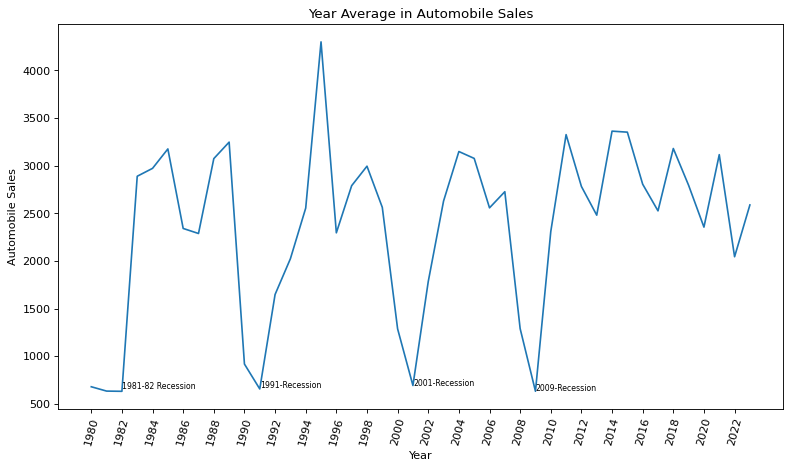

In [ ]:
df_line = df.groupby(df['Year'])['Automobile_Sales'].mean()

plt.figure(figsize=(10, 6))
df_line.plot(kind='line')
plt.xticks(list(range(1980, 2024, 1)), rotation=75)
plt.xlabel('Year')
plt.ylabel('Automobile Sales')
plt.title('Year Average in Automobile Sales')
plt.text(1982, 650, '1981-82 Recession', rotation=45)
plt.text(1991, 655, '1991-Recession', rotation=45)
plt.text(2001, 693, '2001-Recession', rotation=45)
plt.text(2009, 633, '2009-Recession', rotation=45)
plt.legend()
plt.show()

#### TASK 1.2: Plot different lines for categories of vehicle type and analyse the trend to answer the question: Is there a noticeable difference in sales trends between different vehicle types during recession periods?


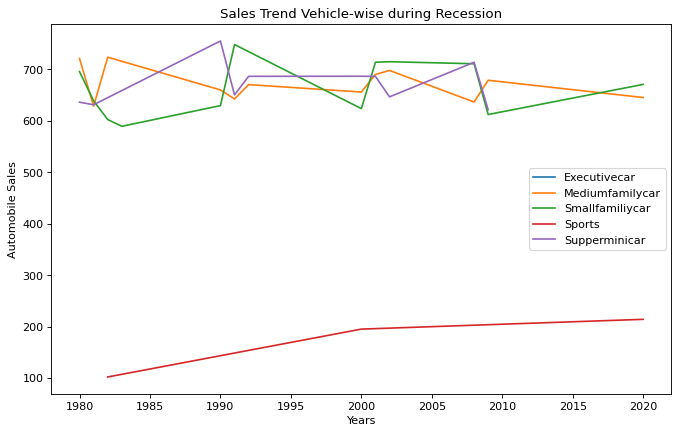

In [ ]:
df_rec = df[df['Recession']==1]
df_Mline = df_rec.groupby(['Year','Vehicle_Type'], as_index=False)['Automobile_Sales'].mean()
df_Mline.set_index('Year', inplace=True)
df_Mline = df_Mline.groupby(['Vehicle_Type'])['Automobile_Sales']
df_Mline.plot(kind='line')
plt.xlabel('Years')
plt.ylabel('Automobile Sales')
plt.title('Sales Trend Vehicle-wise during Recession')
plt.legend()
plt.show()

**Inference:** During recession periods, the sales for Sports type vehicles declined significantly due to their high cost. Meanwhile, sales of Supperminicar and Smallfamilycar increased as consumers shifted toward more affordable options.

### TASK 1.3: Use the functionality of **Seaborn Library** to create a visualization to compare the sales trend per vehicle type for a recession period with a non-recession period.


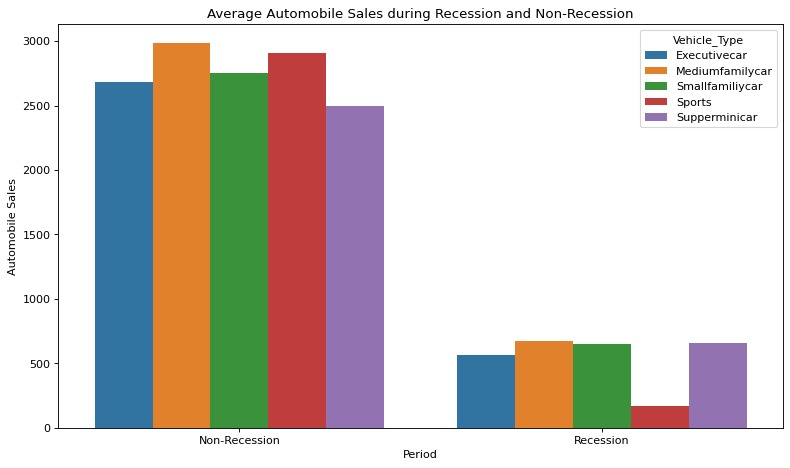

In [ ]:
new_df = df.groupby(['Recession','Vehicle_Type'])['Automobile_Sales'].mean().reset_index()

# Create the bar chart using seaborn
plt.figure(figsize=(10, 6))
sns.barplot(x='Recession', y='Automobile_Sales', hue='Vehicle_Type', data=new_df)
plt.xlabel('Period')
plt.ylabel('Automobile Sales')
plt.title('Average Automobile Sales during Recession and Non-Recession')
plt.xticks(ticks=[0, 1], labels=['Non-Recession', 'Recession'])
plt.show()

**Inference:** During recessions, there is a drastic decline in automobile sales overall. Executive cars and sports cars are the most affected vehicle types during recessions, while smaller, more affordable vehicles (Supperminicar, Smallfamilycar) show greater resilience.

### TASK 1.4: Use sub plotting to compare the variations in GDP during recession and non-recession period by developing line plots for each period.


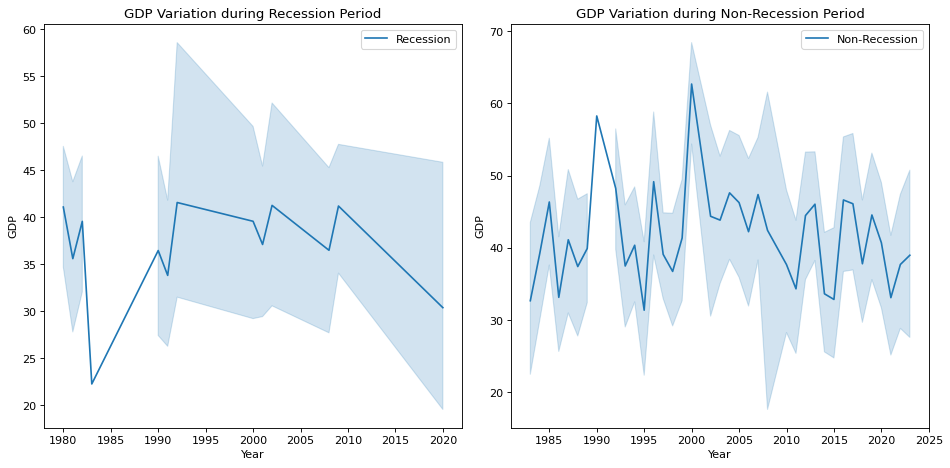

In [ ]:
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]

# Figure
fig = plt.figure(figsize=(12, 6))

# Create different axes for subploting
ax0 = fig.add_subplot(1, 2, 1) # subplot 1 (1 row, 2 columns, first plot)
ax1 = fig.add_subplot(1, 2, 2) # subplot 2 (1 row, 2 columns, second plot)

sns.lineplot(x='Year', y='GDP', data=rec_data, label='Recession', ax=ax0)
ax0.set_xlabel('Year')
ax0.set_ylabel('GDP')
ax0.set_title('GDP Variation during Recession Period')

sns.lineplot(x='Year', y='GDP', data=non_rec_data, label='Non-Recession', ax=ax1)
ax1.set_xlabel('Year')
ax1.set_ylabel('GDP')
ax1.set_title('GDP Variation during Non-Recession Period')

plt.tight_layout()
plt.show()

### TASK 1.5: Develop a Bubble plot for displaying the impact of seasonality on Automobile Sales.

How has seasonality impacted the sales, in which months the sales were high or low? Check it for non-recession years to understand the trend.


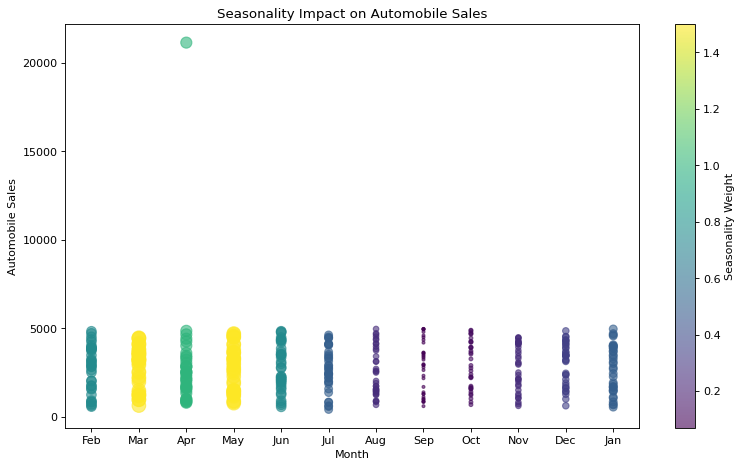

In [ ]:
non_rec_data = df[df['Recession'] == 0]

size = non_rec_data['Seasonality_Weight'] # for bubble effect

sns.scatterplot(
    data=non_rec_data,
    x='Month',
    y='Automobile_Sales',
    size=size,
    hue='Seasonality_Weight',
    legend=False
)

plt.xlabel('Month')
plt.ylabel('Automobile_Sales')
plt.title('Seasonality impact on Automobile Sales')
plt.show()

### TASK 1.6: Use the functionality of Matplotlib to develop a scatter plot to identify the correlation between average vehicle price relate to the sales volume during recessions.


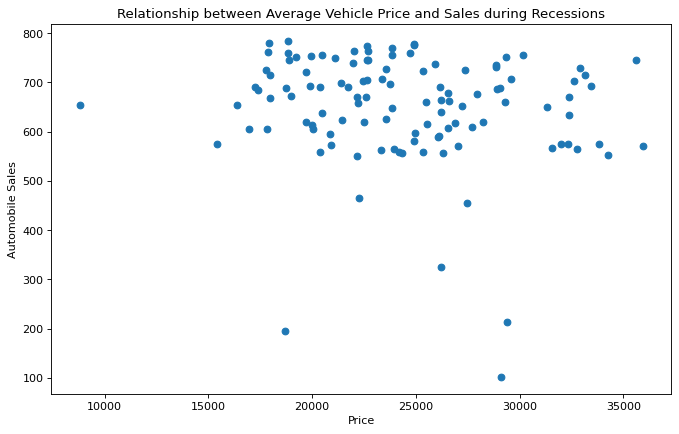

In [ ]:
# Create dataframes for recession and non-recession period
rec_data = df[df['Recession'] == 1]
plt.scatter(rec_data['Price'], rec_data['Automobile_Sales'])

plt.xlabel('Price')
plt.ylabel('Automobile Sales')
plt.title('Relationship between Average Vehicle Price and Sales during Recessions')
plt.show()

### TASK 1.7: Create a pie chart to display the portion of advertising expenditure of XYZAutomotives during recession and non-recession periods.


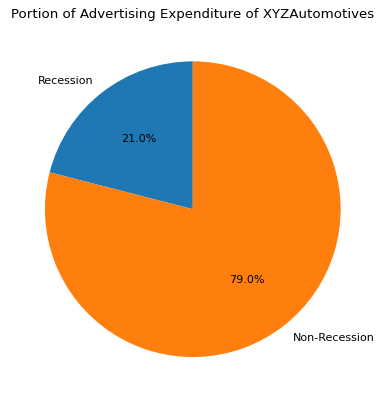

In [ ]:
# Filter the data
Rdata = df[df['Recession'] == 1]
NRdata = df[df['Recession'] == 0]

# Calculate the total advertising expenditure for both periods
RAtotal = Rdata['Advertising_Expenditure'].sum()
NRAtotal = NRdata['Advertising_Expenditure'].sum()

# Create a pie chart for the advertising expenditure
plt.figure(figsize=(8, 6))
labels = ['Recession', 'Non-Recession']
sizes = [RAtotal, NRAtotal]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title('Portion of Advertising Expenditure of XYZAutomotives')
plt.show()

### TASK 1.8: Develop a pie chart to display the total Advertisement expenditure for each vehicle type during recession period.


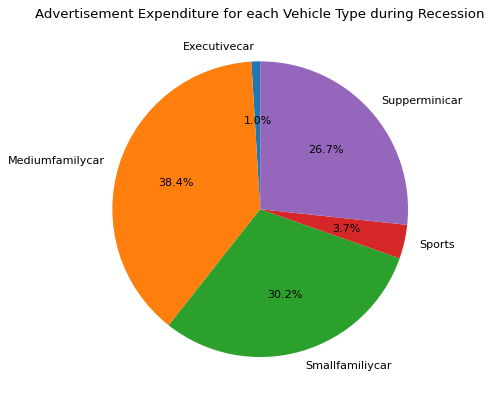

In [ ]:
# Filter the data
Rdata = df[df['Recession'] == 1]

# Calculate the advertising expenditure by vehicle type during recessions
VTexpenditure = Rdata.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()

# Create a pie chart
plt.figure(figsize=(12, 6))
labels = VTexpenditure.index
sizes = VTexpenditure.values
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)
plt.title('Advertisement expenditure for each vehicle type during recession period')
plt.show()

### TASK 1.9: Develop a lineplot to analyse the effect of the unemployment rate on vehicle type and sales during the Recession Period.


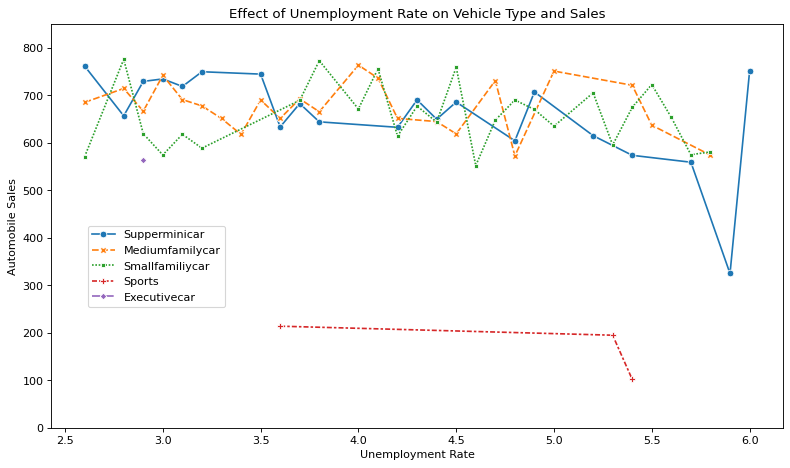

In [ ]:
df_rec = df[df['Recession']==1]
sns.lineplot(
    data=df_rec,
    x='unemployment_rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    style='Vehicle_Type',
    markers=True,
    err_style=None
)

plt.ylim(0, 850)
plt.legend(loc=(0.05, .3))
plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.title('Effect of Unemployment Rate on Vehicle Type and Sales')
plt.show()

**Inference:** During recession, when unemployment rate rises, automobile sales decline across all vehicle types. However, affordable vehicles (Supperminicar, Smallfamilycar, Mediumfamilycar) maintain relatively higher sales compared to luxury segments like Sports and Executive cars, which drop sharply as unemployment increases.

### OPTIONAL: TASK 1.10 Create a map on the highest sales region/offices of the company during recession period

In [ ]:
path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/us-states.json'

import requests
us_states_json = requests.get(path).json()

recession_data = df[df['Recession'] == 1]

# Calculate the total sales by city
sales_by_city = recession_data.groupby('City')['Automobile_Sales'].sum().reset_index()

# Create a base map centered on the United States
map1 = folium.Map(location=[37.0902, -95.7129], zoom_start=4)

# Create a choropleth layer using Folium
choropleth = folium.Choropleth(
    geo_data=us_states_json,
    data=sales_by_city,
    columns=['City', 'Automobile_Sales'],
    key_on='feature.properties.name',
    fill_color='YlOrRd',
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name='Automobile Sales during Recession').add_to(map1)

# Add tooltips to the choropleth layer
choropleth.geojson.add_child(
    folium.features.GeoJsonTooltip(['name'], labels=True)
)

# Display the map
map1

<folium.folium.Map object at 0x...>

# Congratulations! You have completed the lab

**Author:** XYZ Automotives Analytics Team

Copyright © 2023 IBM Corporation. All rights reserved.